## <span style="color:purple"> Graph Time Series Plots Stacking Each Year </span>

<span style="color:purple"> These graphs will plot series data by day of the year, and then each year will be stacked on top of one another. The purpose of this is to visually inspect the variation in seasonality year-to-year, providing a basis to investigate interannual changes. </span>

### <span style="color:purple"> Plotting function </span>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from FilterFunctions import apply_lowpass_filter, lowpass_filter
import numpy as np

# Define global colour mapping for each year to ensure consistency across boreholes and MicroCATs
colours = {
    2001: "tab:blue",   2002: "tab:orange", 2003: "tab:green",
    2004: "tab:red",    2005: "tab:purple", 2006: "tab:brown",
    2007: "tab:pink",   2008: "tab:olive",  2009: "tab:cyan",
    2010: "darkblue",   2011: "crimson",    2012: "teal",
    2013: "goldenrod",
}

def plot_doy(df, borehole, cat, ylim_temp=None, ylim_sal=None):
    # Create a mask to filter the dataframe for the specified borehole and cat
    mask = (df["borehole"] == borehole) & (df["cat"] == cat)
    sub = df[mask].copy()
    
    # Extract day of year and year from the time column
    sub["doy"] = sub["time"].dt.dayofyear + sub["time"].dt.hour / 24 + sub["time"].dt.minute / 1440
    sub["year"] = sub["time"].dt.year

    # Get the unique years in the subset
    years = sorted(sub["year"].unique())

    # Round to nearest half-hour (1/48 of a day) since each MicroCAT records data with a half-hour interval, although due to time drift
    # the equivalent timestamp on different years may not be exactly the same time to the second
    sub["doy_bin"] = (sub["doy"] * 48).round() / 48

    # Calculate the median temp and salinity values on the equivalent timestamp between different years
    temp_median_raw = sub.groupby("doy_bin")["potential_temperature"].agg("median")
    salinity_median_raw = sub.groupby("doy_bin")["practical_salinity"].agg("median")

    # Retain the DOY index to be able to plot the smoothed median values
    doy_index = temp_median_raw.index

    # Since our lowpass filter uses .sosfiltfilt(), it applies the filter forwards and backwards through time
    # However, the data at the start and end of the year does not have data before and after it, respectively
    # We need to pad the data either side to treat the multi-year median as continuous
    # This is reasonable given that the seasonal data is naturally cyclic

    # Create a pad either side which is twice the length of the cutoff_period
    n_pad = int((cutoff_period * 2) / sampling_interval)

    # Pad the median values by concatenating at the start and end equivalent to the designed length of the pad
    temp_padded = np.concatenate([temp_median_raw.values[-n_pad:], temp_median_raw.values, temp_median_raw.values[:n_pad]])
    salinity_padded = np.concatenate([salinity_median_raw.values[-n_pad:], salinity_median_raw.values, salinity_median_raw.values[:n_pad]])

    # Apply the filter function to the padded median values
    temp_median_filtered = lowpass_filter(temp_padded, cutoff_period=cutoff_period, sampling_interval=sampling_interval, max_gap_hours=max_gap_hours)
    salinity_median_filtered = lowpass_filter(salinity_padded, cutoff_period=cutoff_period, sampling_interval=sampling_interval, max_gap_hours=max_gap_hours)

    # Remove the padded data from the filtered data
    temp_median_smooth = temp_median_filtered[n_pad:-n_pad]
    salinity_median_smooth = salinity_median_filtered[n_pad:-n_pad]

    # sharex=True to share the x-axis between the two subplots
    fig, (axT, axS) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    for year in years:
        # Filter the subset for the current year
        year_data = sub[sub["year"] == year]
        
        # Plot raw data
        axT.plot(year_data["doy"], year_data["potential_temperature"], lw=0.8, color="gainsboro", label="_", zorder=1)
        axS.plot(year_data["doy"], year_data["practical_salinity"], lw=0.8, color="gainsboro", label="_", zorder=1)

        # Plot smoothed data
        # For close dotted line use: linestyle=(0, (1,1))
        axT.plot(year_data["doy"], year_data["potential_temperature_smooth"], lw=0.8, label=str(year), linestyle=(0, (1,1)), color=colours[year], zorder=2)
        axS.plot(year_data["doy"], year_data["practical_salinity_smooth"], lw=0.8, label=str(year), linestyle=(0, (1,1)), color=colours[year], zorder=2)

    axT.plot(doy_index, temp_median_smooth, lw=2, color="black", label="Median", zorder=3)
    axS.plot(doy_index, salinity_median_smooth, lw=2, color="black", label="Median", zorder=3)

    position = sub["water_column_position"].iloc[0]

    axT.set_ylabel("Potential Temperature (°C)")
    axS.set_ylabel("Practical Salinity (PSS78)")
    axS.set_xlabel("Day of Year")
    axT.set_title(f"{borehole} {position.capitalize()} MicroCAT cat{cat}: Temperature & Salinity")

    axT.legend(ncols=3)
    axS.legend(ncols=3)

    if ylim_temp is not None: axT.set_ylim(*ylim_temp)
    if ylim_sal  is not None: axS.set_ylim(*ylim_sal)

    axT.set_xlim(0, 366)
    axS.set_xlim(0, 366)

    axT.grid(True); axS.grid(True)
    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Import and apply filtering to DataFrame </span>

<span style="color:purple"> When filtering using a large cutoff period it is often necessary to rely on interpolation
to fill gaps in the data which result from minor discontinuities in data collection. In the below script, we can define the length
of gaps which we are comfortable interpolating across. If we wish not to interpolate, we can set this variable to 0. </span>

In [2]:
df = pd.read_parquet("../data/proc/03_pressure_handled.parquet")

# Define the cutoff period for filtering in days 
cutoff_period_days = 30  # days
cutoff_period=cutoff_period_days*24

# The sampling interval is 0.5 hours, given that each MicroCAT records observations every 30 minutes
sampling_interval=0.5

# Define a period of time in days for less than which we are comfortable interpolating for 
# Set this to 0 for no interpolation
interpolate_days = 7 # days
max_gap_hours=interpolate_days*24

# Apply filtering to the DataFrame
# NOTE: cutoff_period is defined in terms of hours
df_filtered = apply_lowpass_filter(df, cutoff_period, sampling_interval, max_gap_hours)

### <span style="color:purple"> Plot time series graphs of temp and salinity for each borehole/cat by day of the year </span>

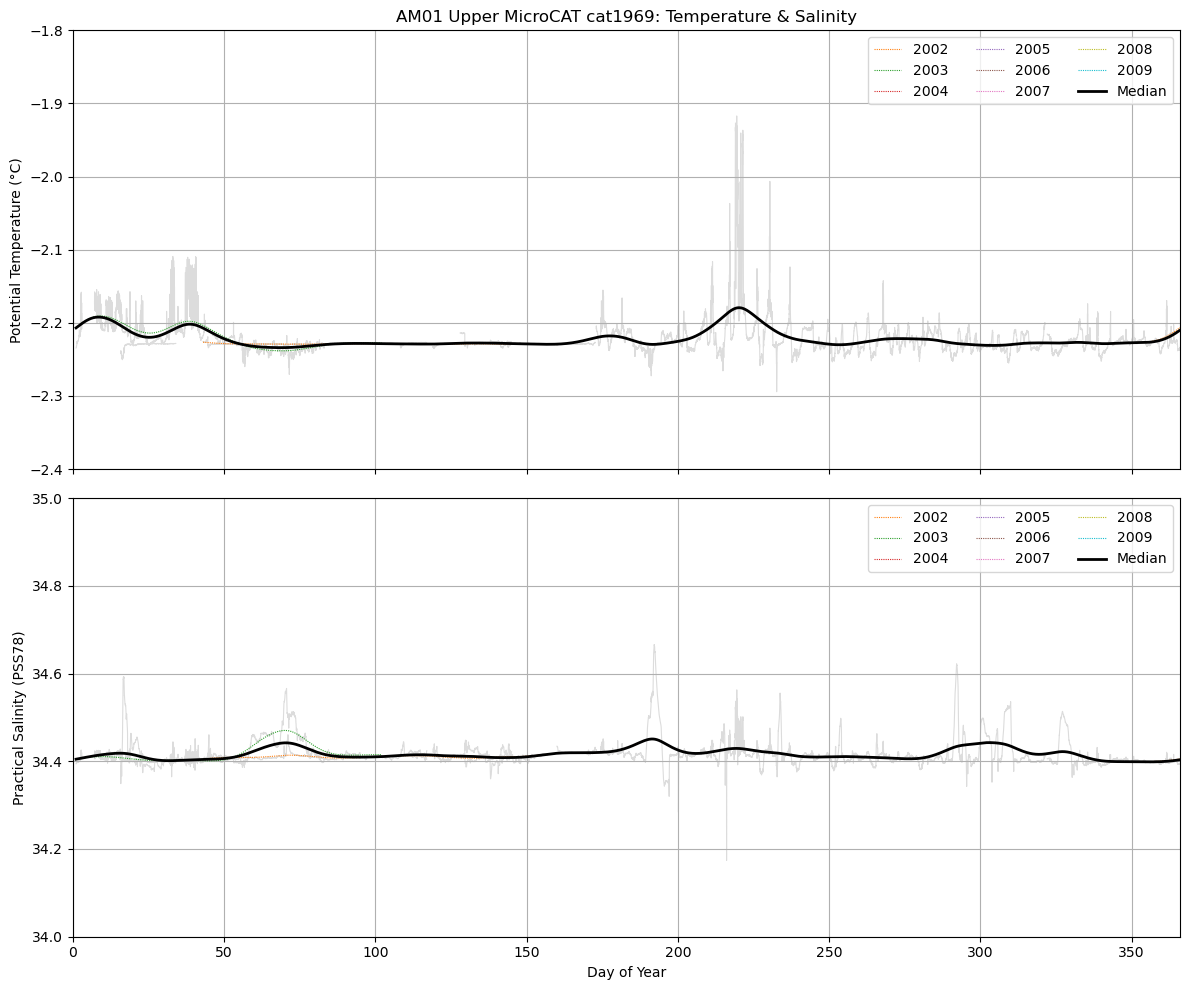

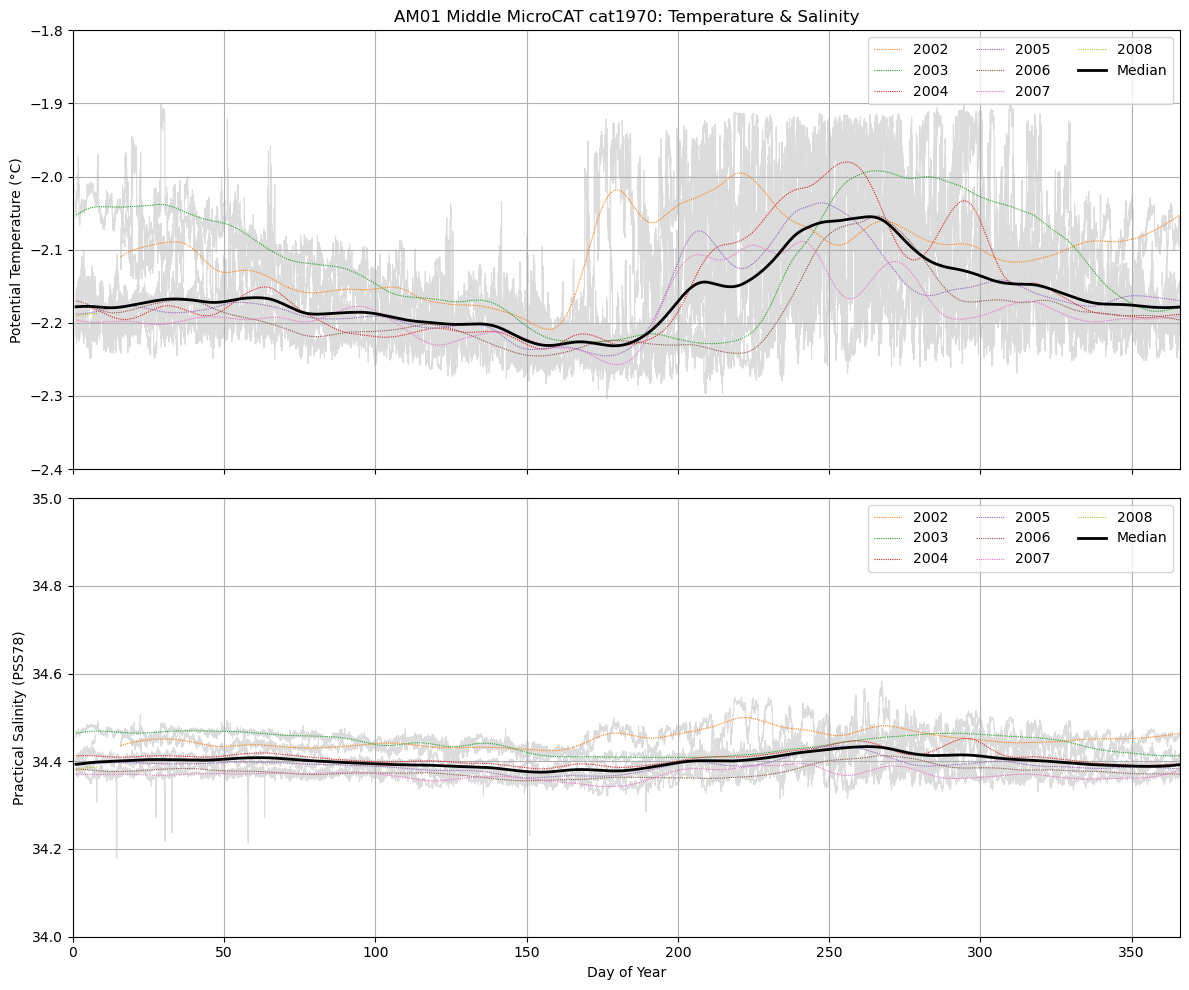

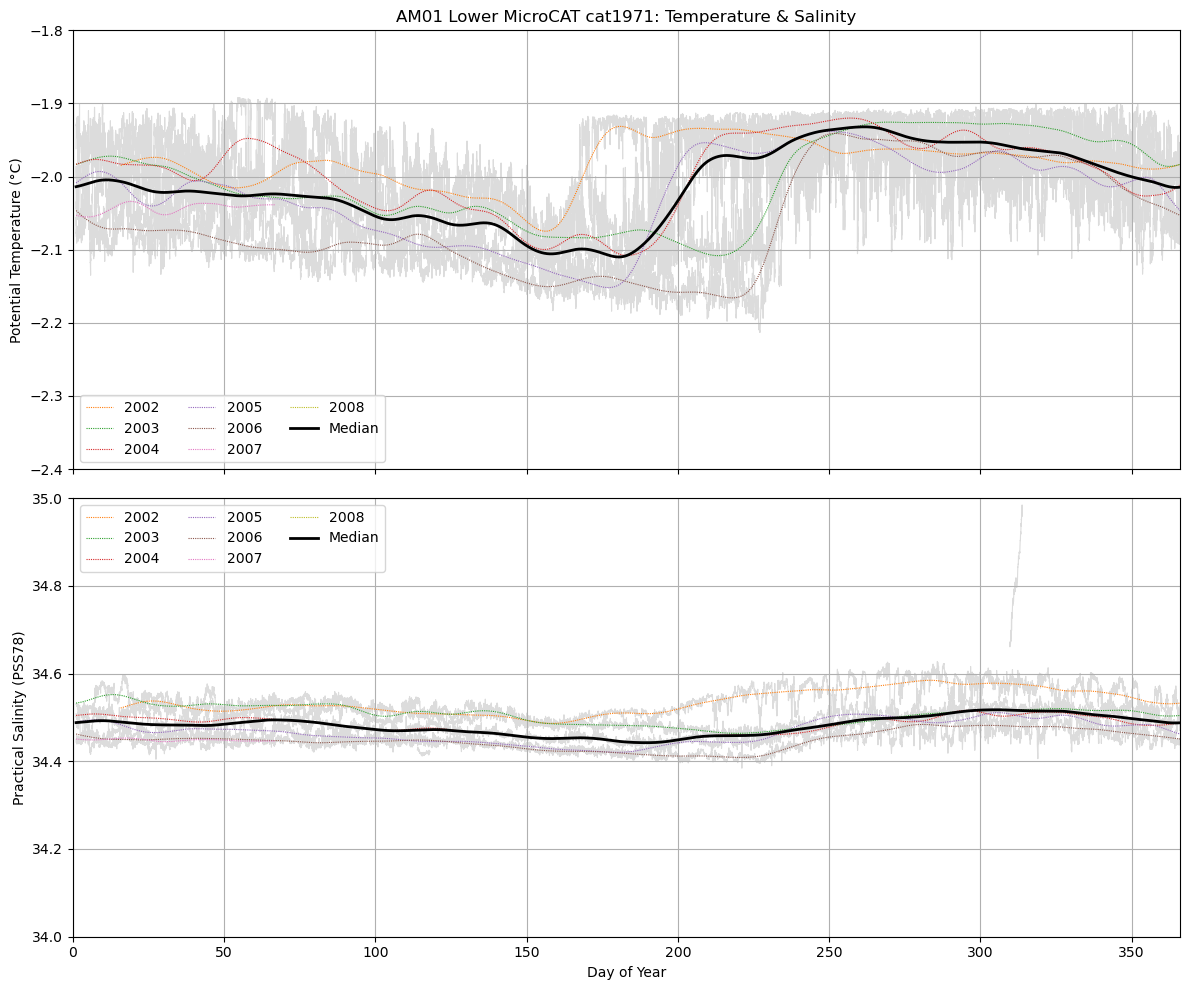

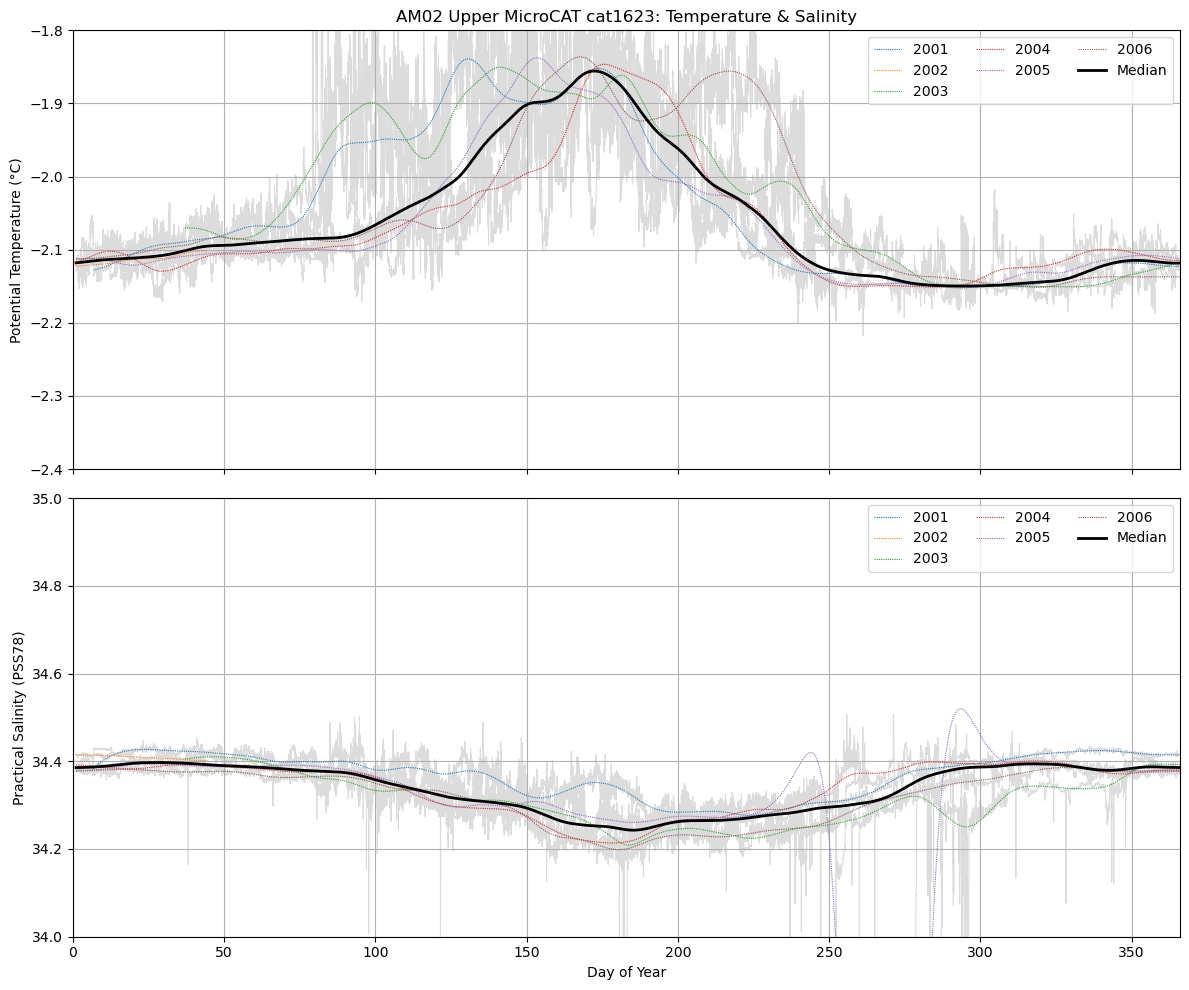

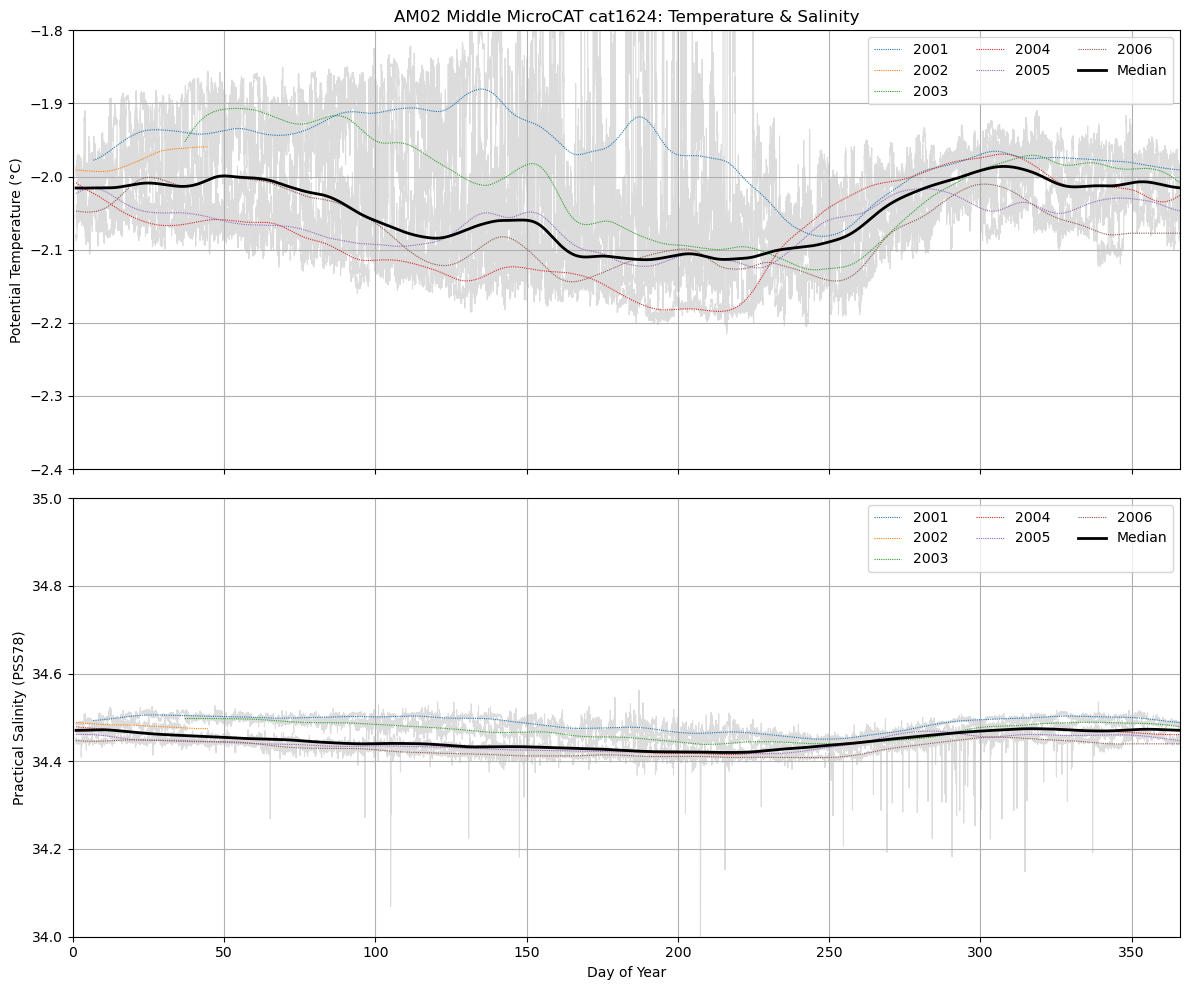

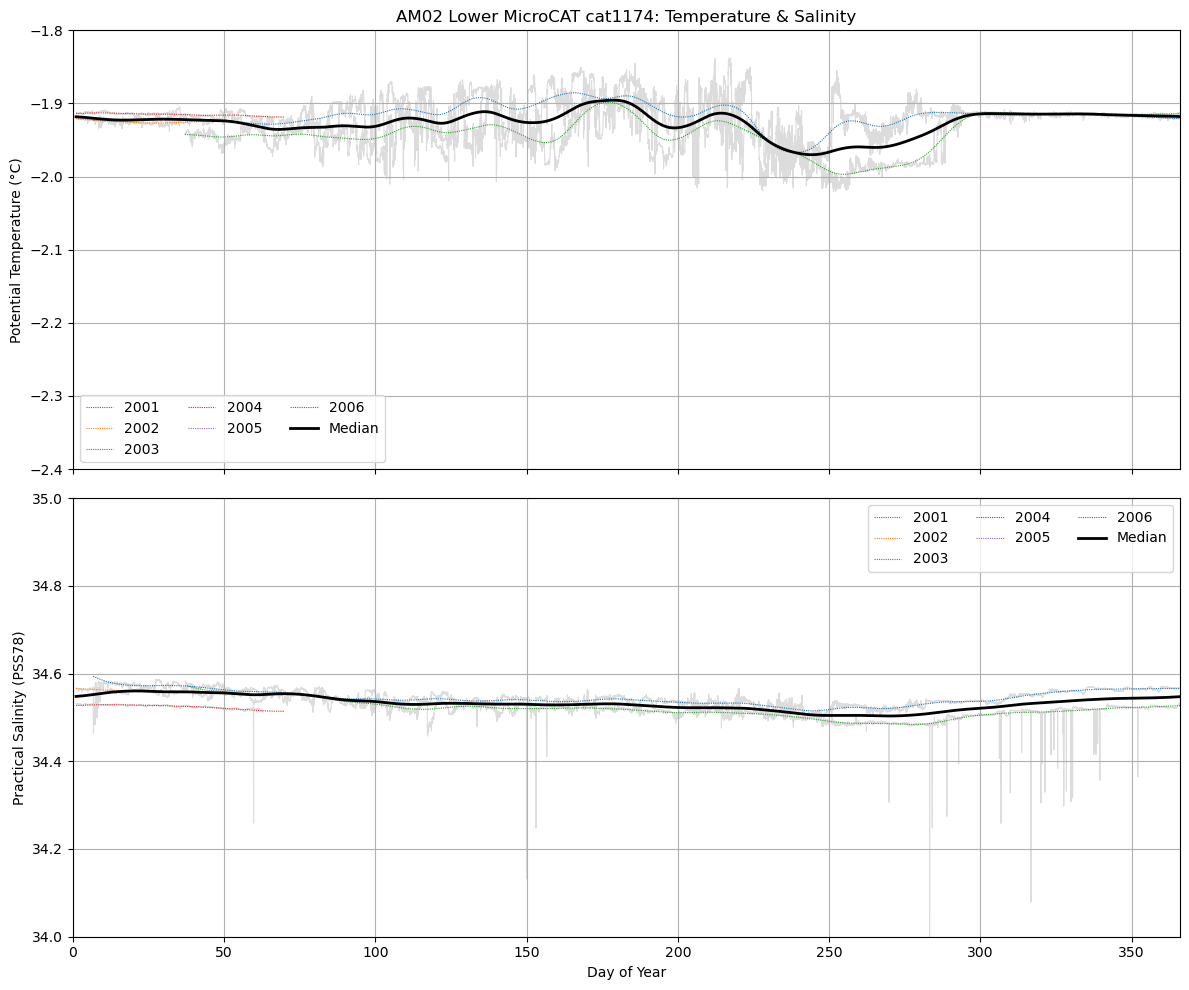

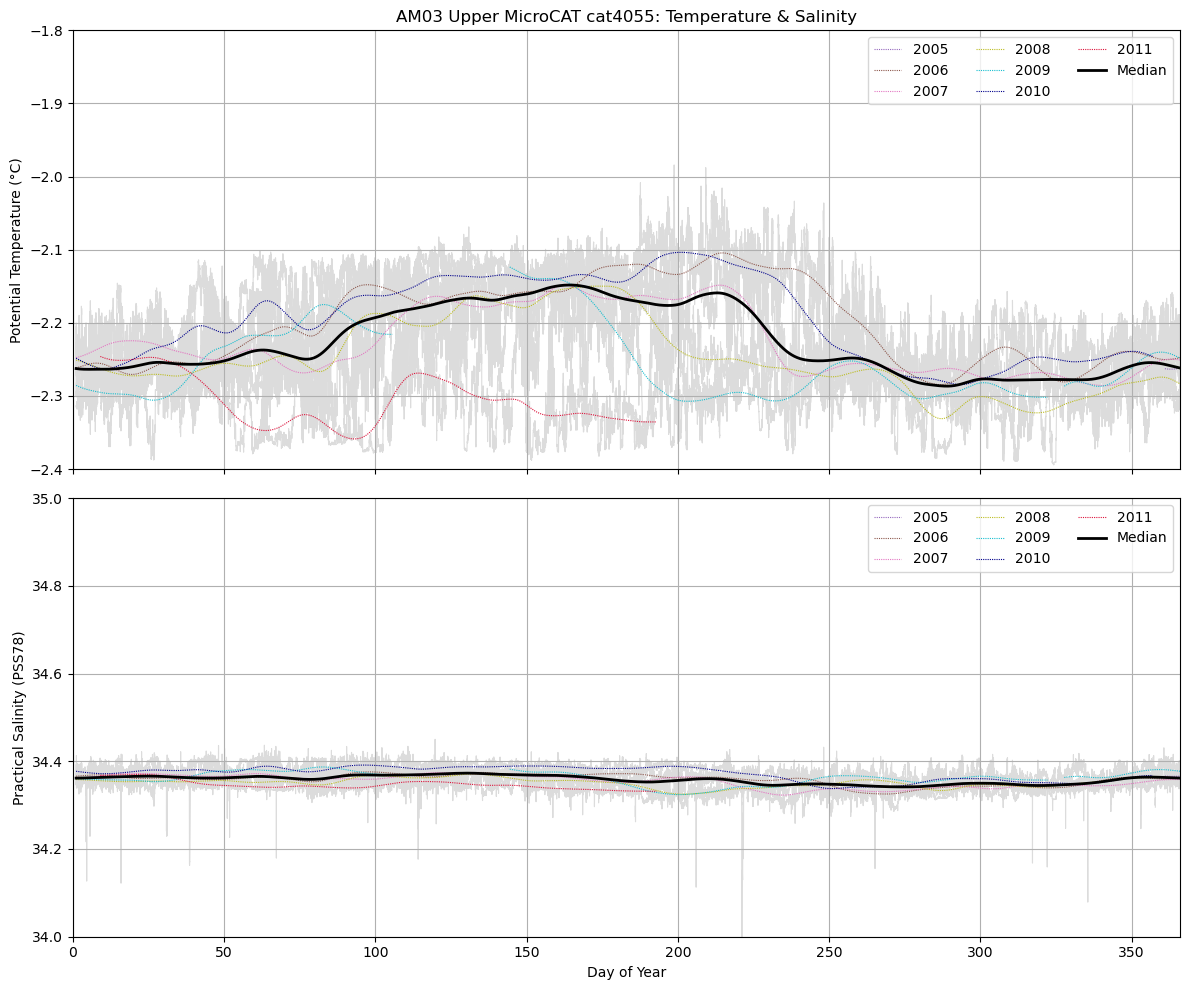

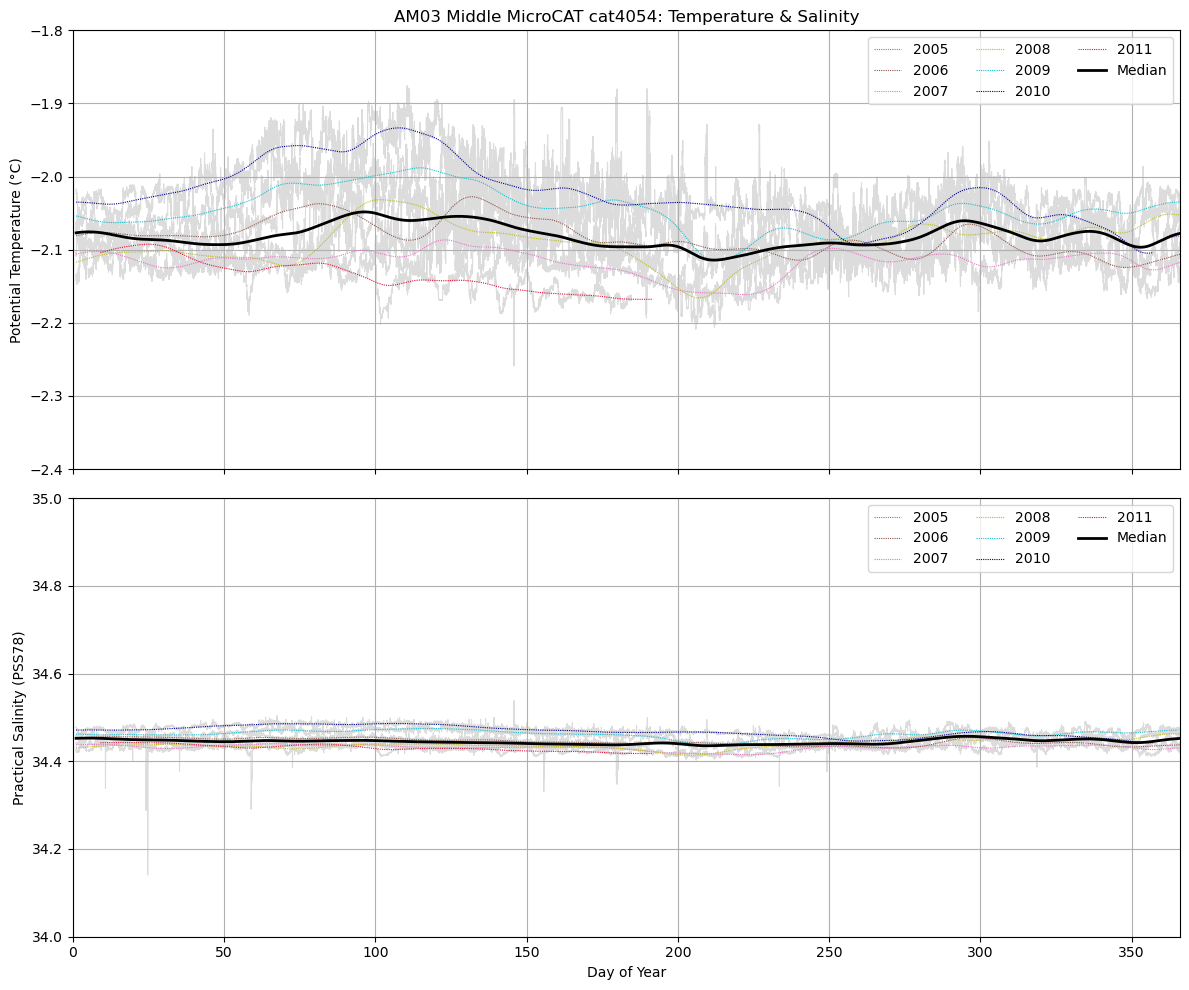

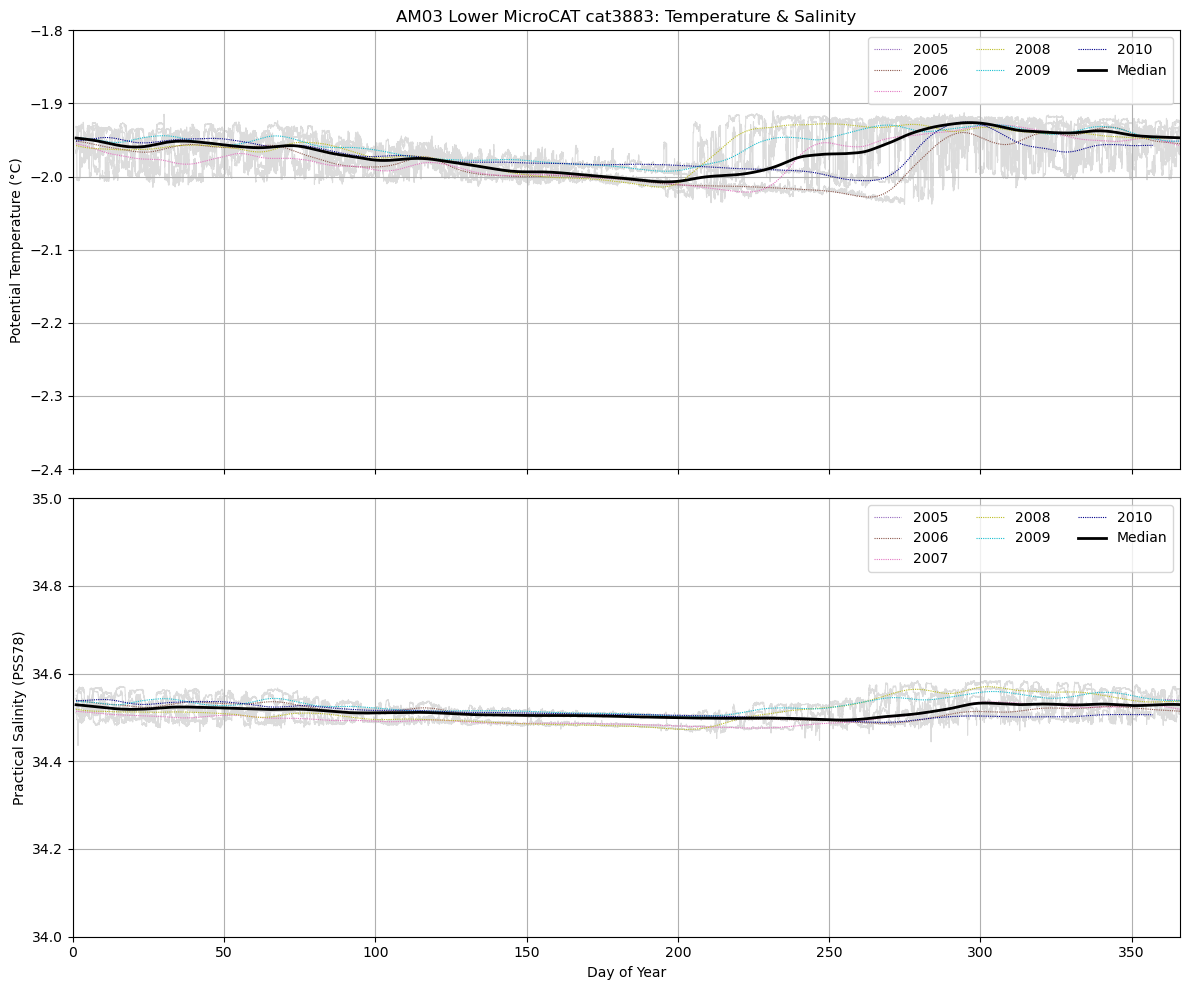

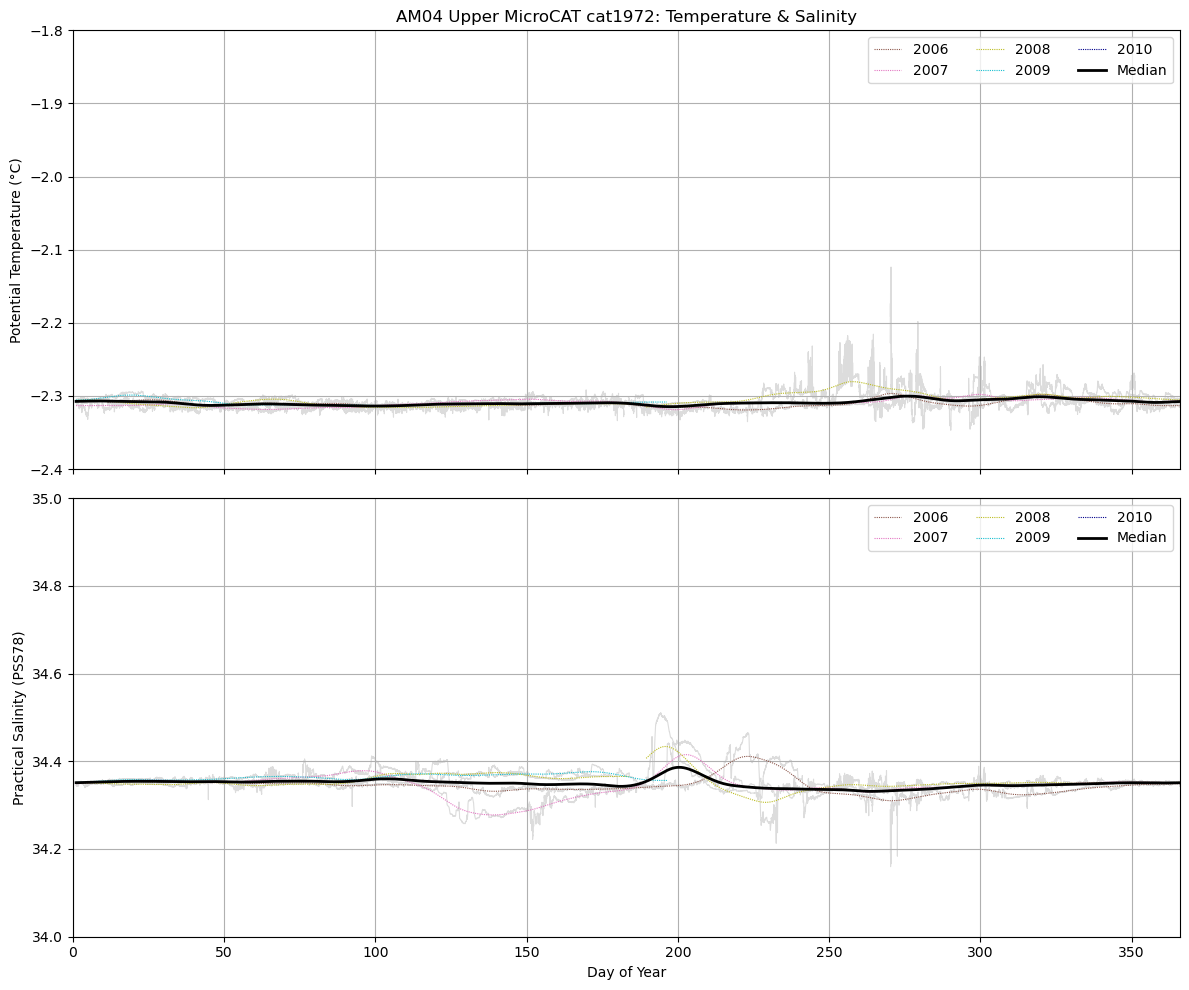

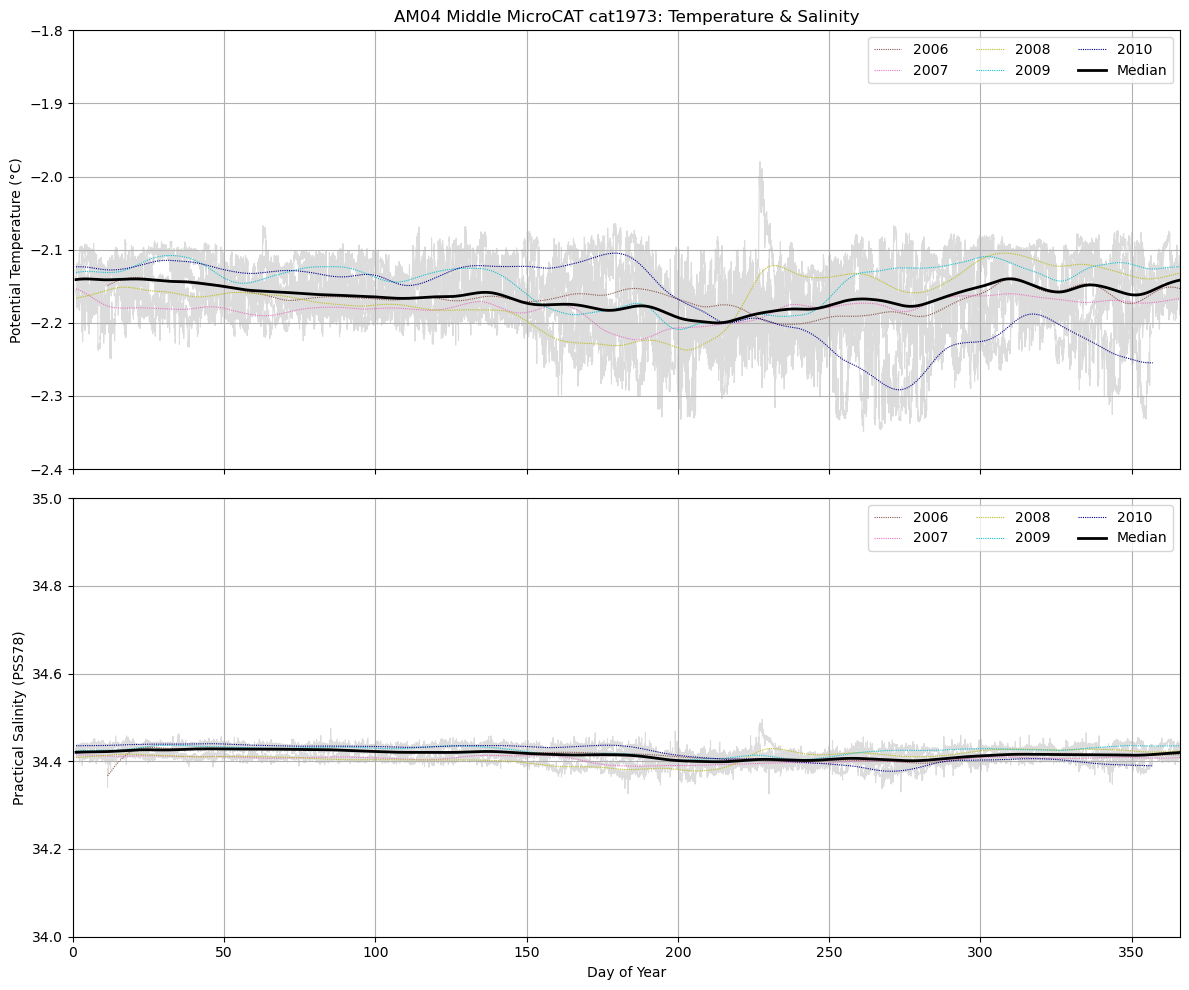

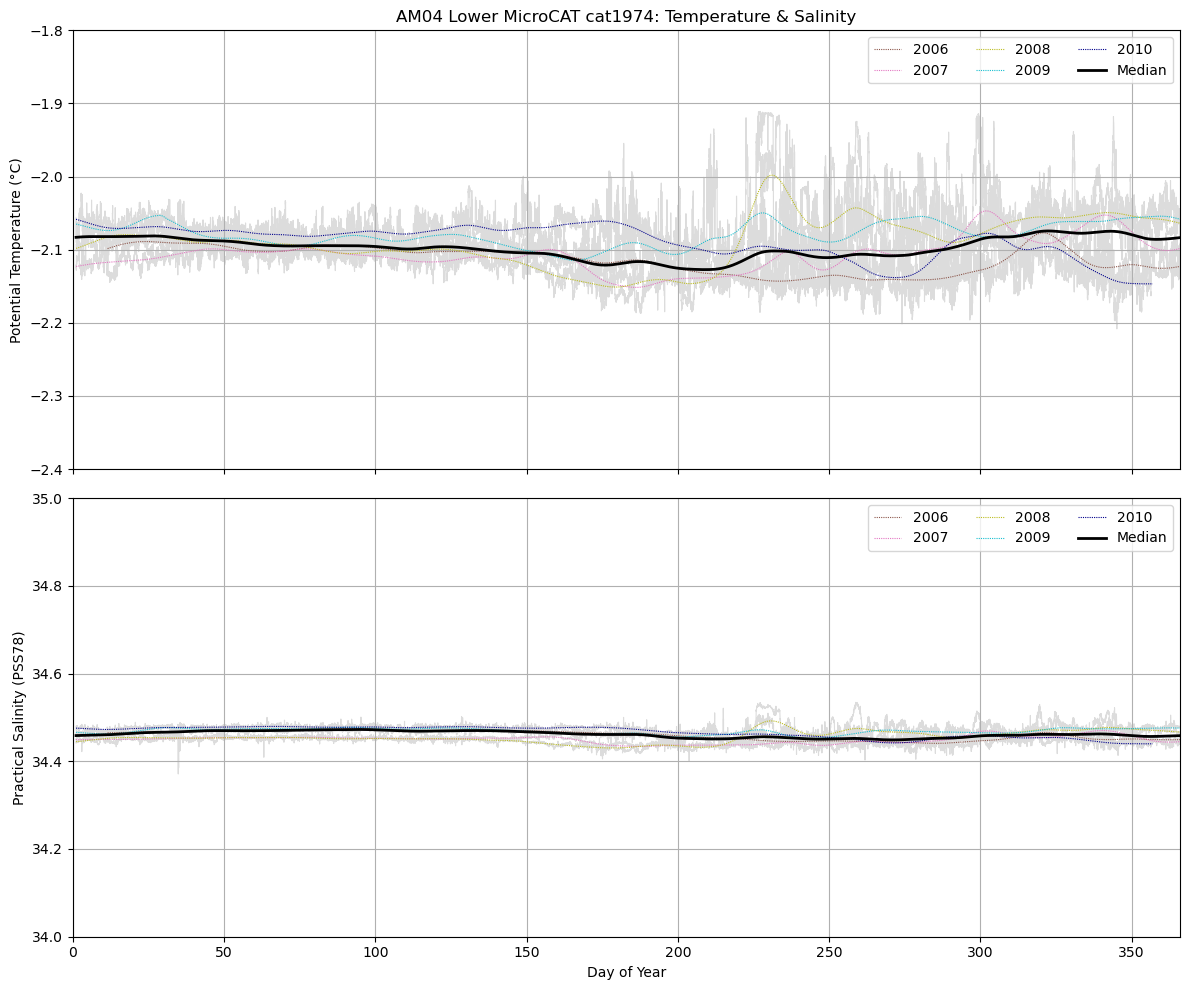

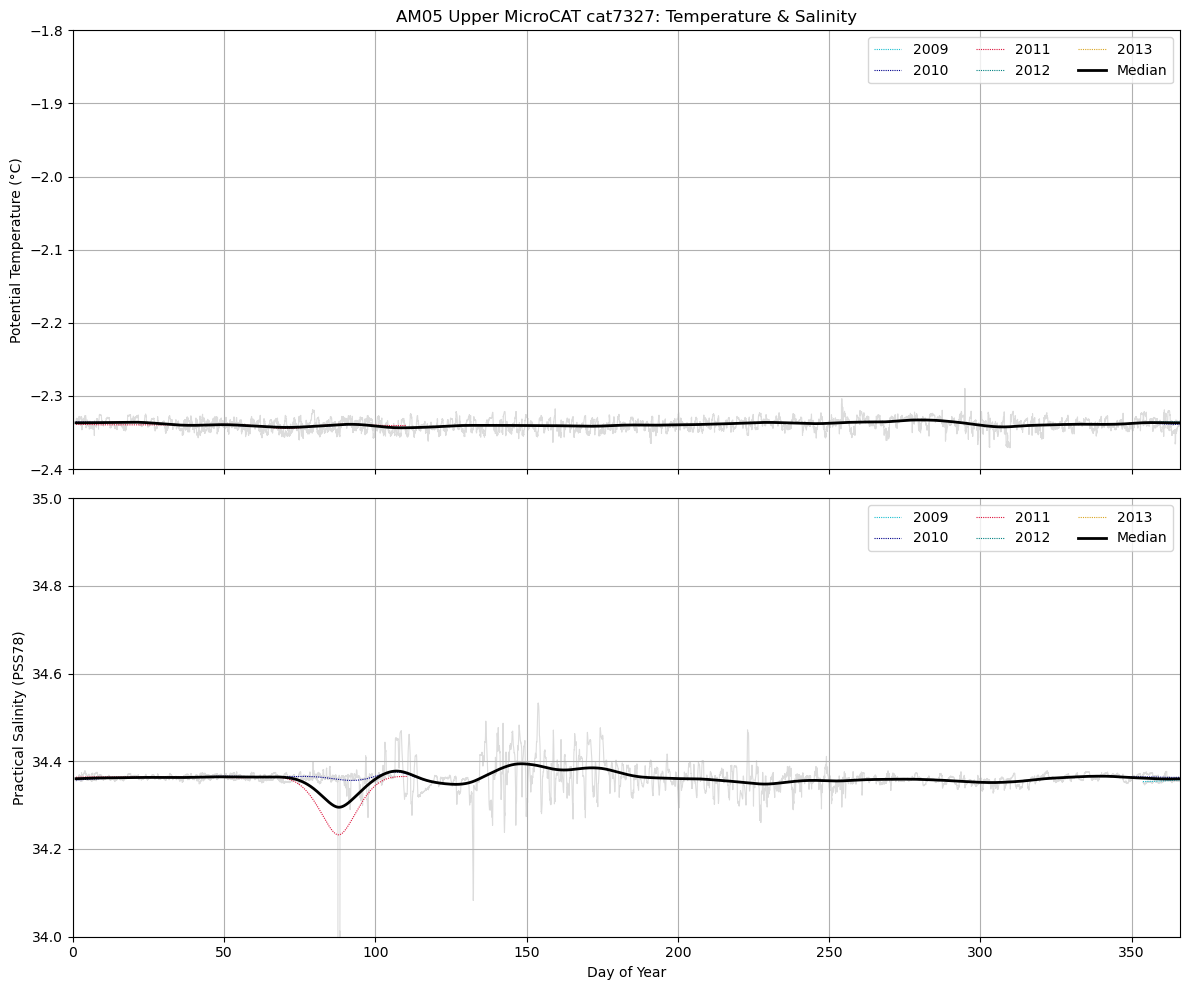

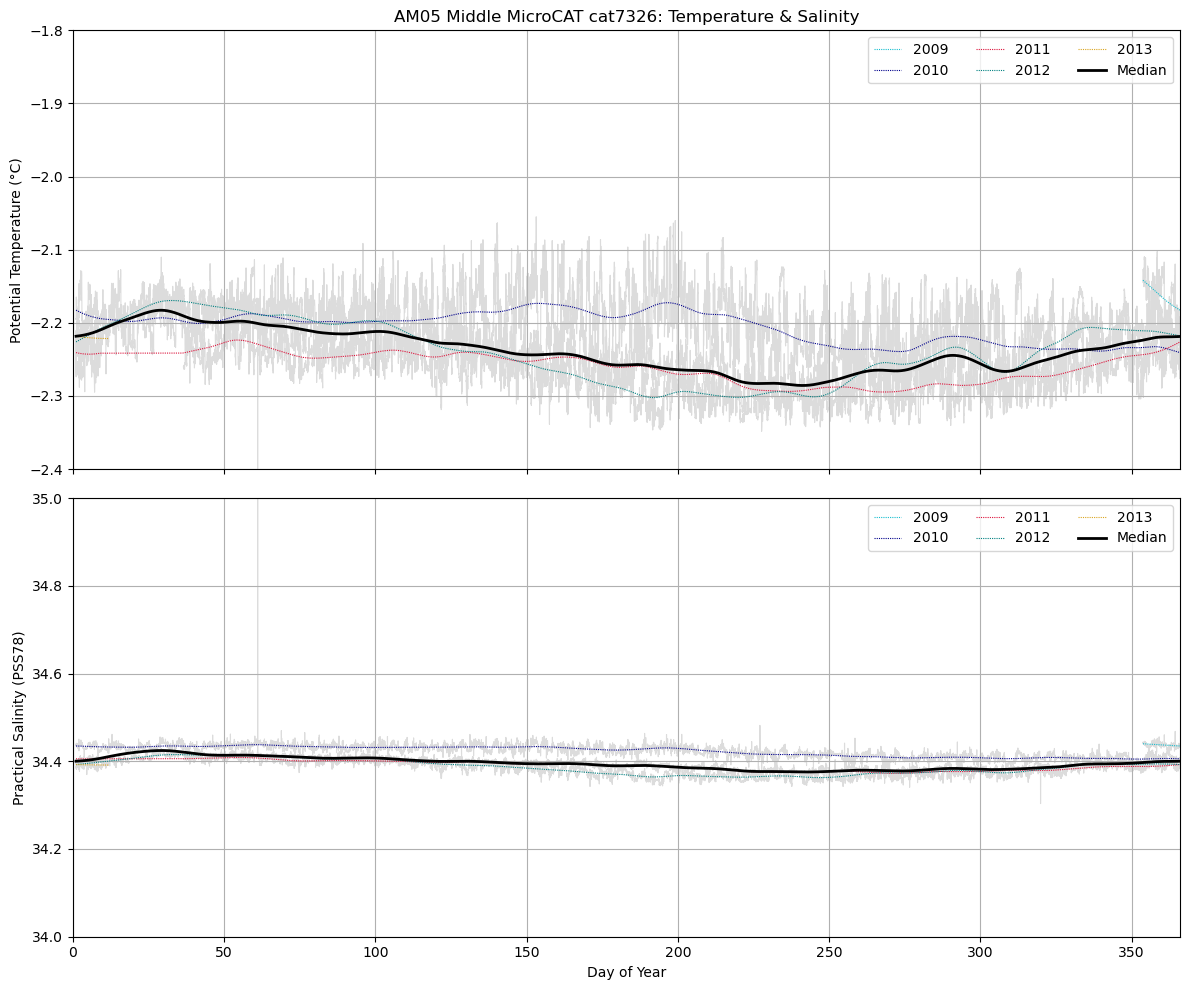

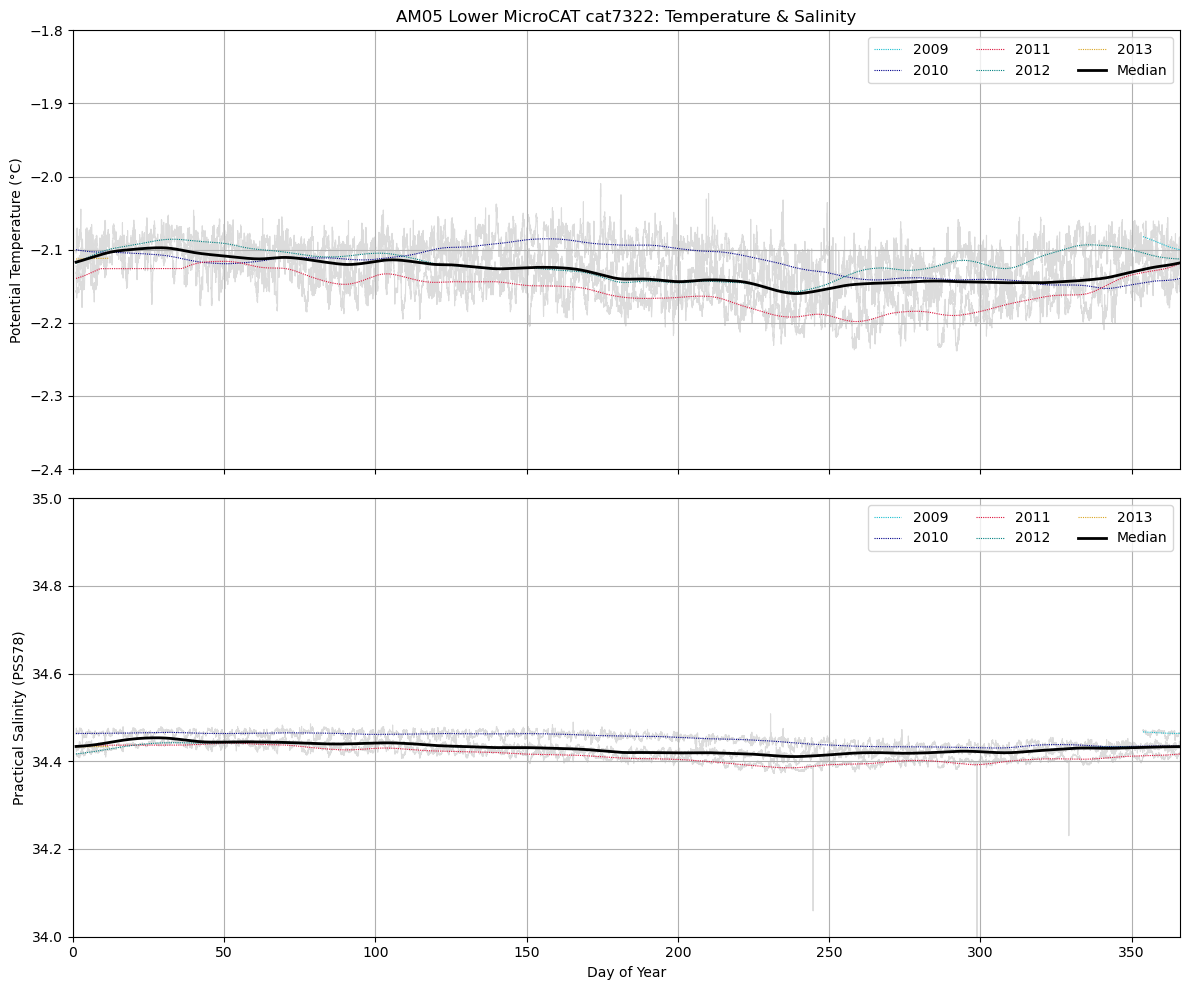

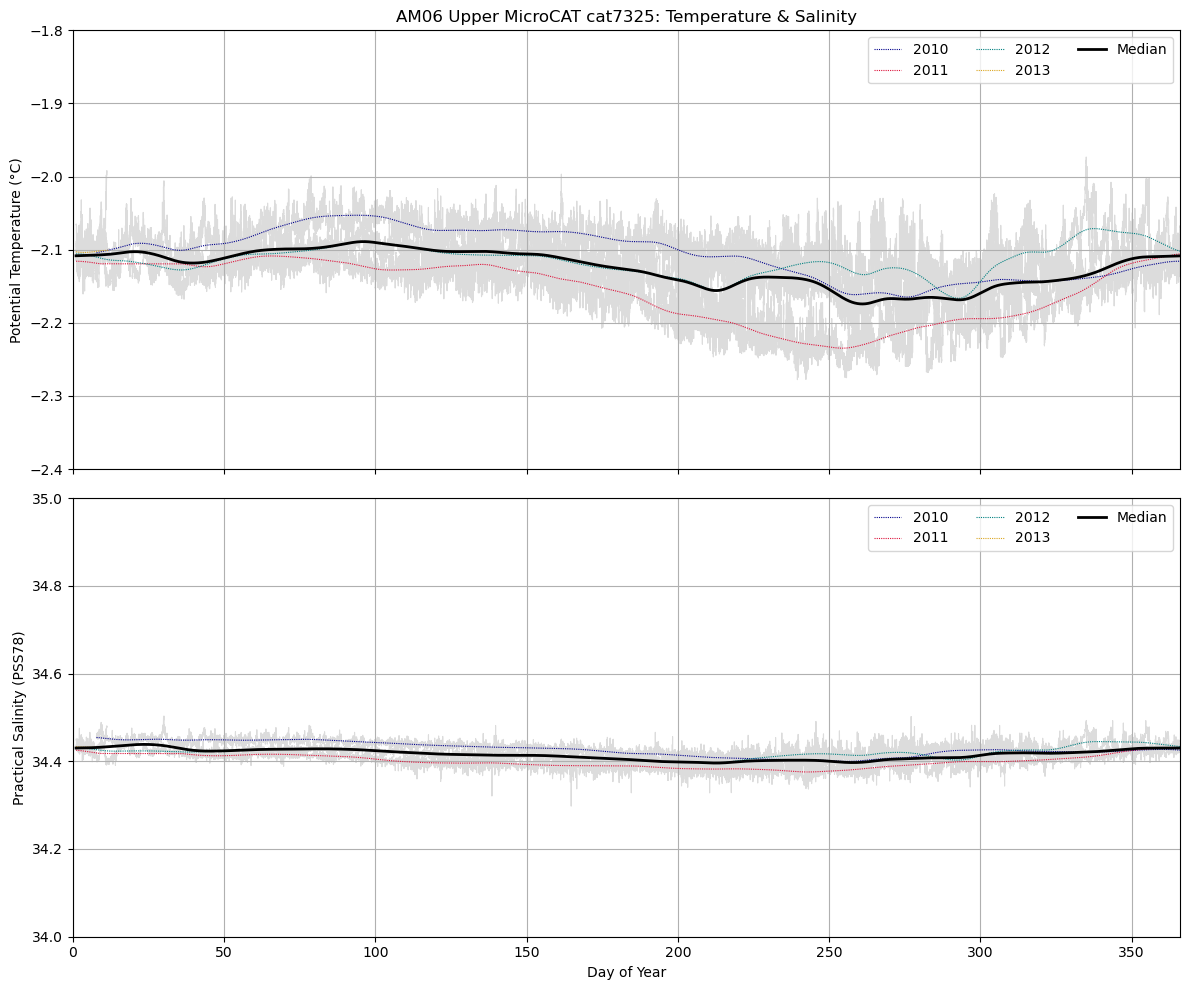

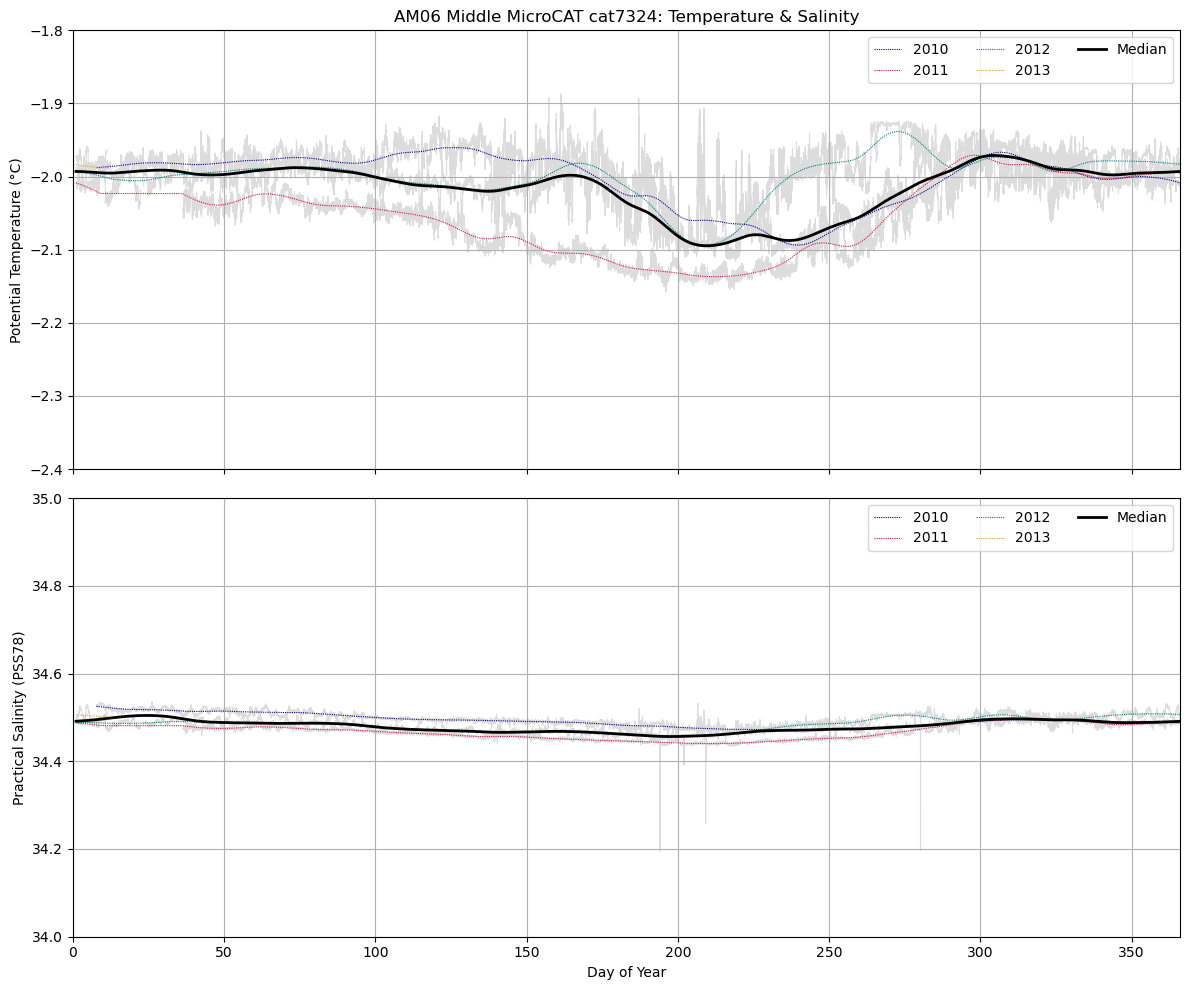

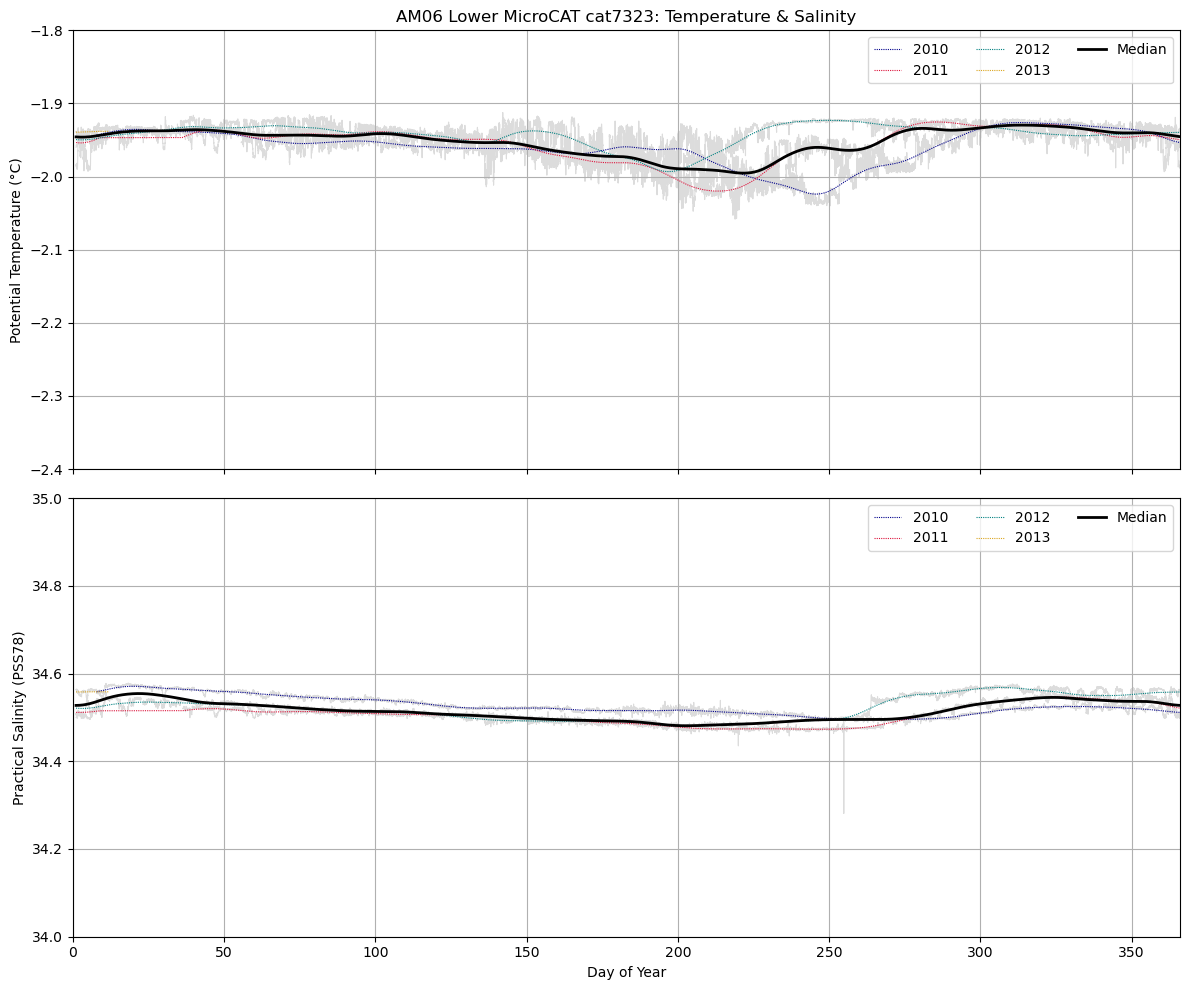

In [3]:
# Define the limits of the y-axes for plots of temperature and salinity
ylim_temp = (-2.4, -1.8)
ylim_sal = (34, 35)

boreholes = sorted(df_filtered["borehole"].unique())

for borehole in boreholes:
    df_bh = df[df["borehole"] == borehole]

    # Build a list to force ordered plotting of the upper, then middle, then lower MicroCAT
    position_order = ["upper", "middle", "lower"]

    for position in position_order:
        cats = df_bh[df_bh["water_column_position"] == position]["cat"].unique()

        for cat in cats:
            plot_doy(df, borehole, cat, ylim_temp=ylim_temp, ylim_sal=ylim_sal)